In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import os
print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [2]:
inicio = time.perf_counter()

df = pd.read_parquet(
    "../data/dataset_5M.parquet"
)

fin = time.perf_counter()

tiempo_lectura = fin - inicio

print(
    "Tiempo de lectura:",
    tiempo_lectura,
    "segundos"
)

Tiempo de lectura: 0.342848900007084 segundos


In [3]:
# Dimensiones
filas, columnas = df.shape
print("Filas:", filas)
print("Columnas:", columnas)

# Memoria RAM utilizada por el DataFrame
memoria_bytes = df.memory_usage(deep=True).sum()
memoria_mb = memoria_bytes / (1024 ** 2)
print("Memoria utilizada:", memoria_mb, "MB")

# Tamaño del archivo Parquet en disco
tamaño_bytes = os.path.getsize("../data/dataset_5M.parquet")
tamaño_mb = tamaño_bytes / (1024 ** 2)
print("Tamaño del archivo en disco:", tamaño_mb, "MB")

Filas: 5000000
Columnas: 5
Memoria utilizada: 371.93310928344727 MB
Tamaño del archivo en disco: 123.83417892456055 MB


In [4]:
estadisticas = df.describe()

estadisticas

,edad,ingresos,altura,experiencia
count,5.000000e+06,5.000000e+06,5.000000e+06,5.000000e+06
mean,3.999782e+01,2.495966e+04,1.700005e+02,1.999638e+01
std,1.200138e+01,1.330275e+04,1.000088e+01,1.183172e+01
min,-1.976175e+01,1.639865e+03,1.188103e+02,0.000000e+00
25%,3.189826e+01,1.571939e+04,1.632550e+02,1.000000e+01
50%,4.000047e+01,2.202656e+04,1.700080e+02,2.000000e+01
75%,4.809160e+01,3.086169e+04,1.767452e+02,3.000000e+01
max,1.004057e+02,2.995457e+05,2.207648e+02,4.000000e+01


In [5]:
print(
    "Media de edad:",
    df["edad"].mean()
)

Media de edad: 39.997821996896825


In [6]:
print(
    "Desviación estándar de edad:",
    df["edad"].std()
)

Desviación estándar de edad: 12.001379025220247


In [7]:
print(
    "Mínimo:",
    df["edad"].min()
)

print(
    "Máximo:",
    df["edad"].max()
)

Mínimo: -19.761751173733877
Máximo: 100.40566326613538


In [8]:
cuantiles = df["edad"].quantile(
    [0.25, 0.50, 0.75]
)

cuantiles

0.25    31.898256
0.50    40.000473
0.75    48.091603
Name: edad, dtype: float64

In [9]:
estadisticas.to_csv(
    "../resultados/tablas/baseline_estadisticas.csv"
)


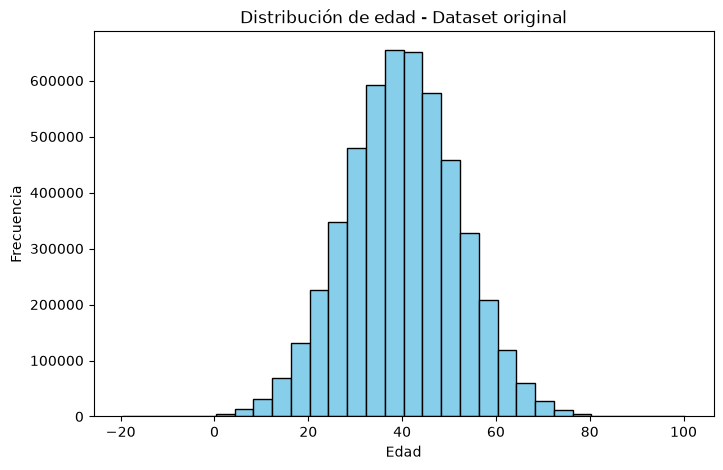

Gráfico baseline_edad.png guardado.


In [16]:
plt.figure(figsize=(8, 5))
plt.hist(df["edad"], bins=30, color='skyblue', edgecolor='black')
plt.title("Distribución de edad - Dataset original")
plt.xlabel("Edad")
plt.ylabel("Frecuencia")


plt.savefig("../resultados/graficos/baseline_edad.png", dpi=300, bbox_inches="tight")
plt.show()
print("Gráfico baseline_edad.png guardado.")

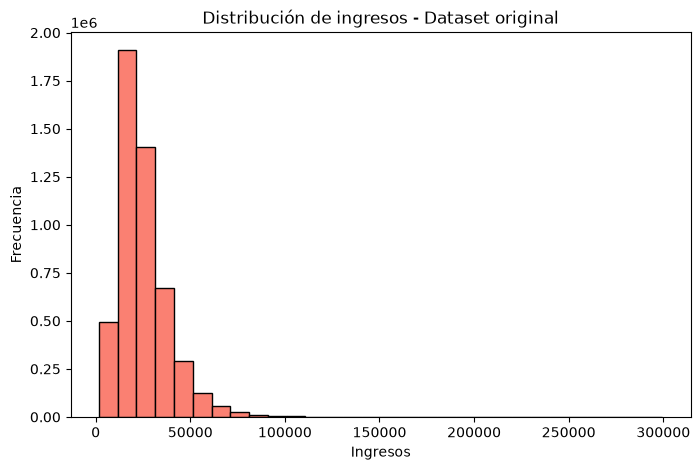

Gráfico baseline_ingresos.png guardado.


In [17]:
plt.figure(figsize=(8, 5))
plt.hist(df["ingresos"], bins=30, color='salmon', edgecolor='black')
plt.title("Distribución de ingresos - Dataset original")
plt.xlabel("Ingresos")
plt.ylabel("Frecuencia")


plt.savefig("../resultados/graficos/baseline_ingresos.png", dpi=300, bbox_inches="tight")
plt.show()
print("Gráfico baseline_ingresos.png guardado.")

In [12]:
baseline = pd.DataFrame({
    "Metrica": [
        "Filas",
        "Columnas",
        "Tiempo de lectura (s)",
        "Memoria (MB)",
        "Tamaño archivo (MB)",
        "Media edad",
        "Desv. estándar edad"
    ],
    "Valor": [
        filas,
        columnas,
        tiempo_lectura,
        memoria_mb,
        tamaño_mb,
        df["edad"].mean(),
        df["edad"].std()
    ]
})

# Guardar tabla baseline en CSV
baseline.to_csv("../resultados/tablas/baseline.csv", index=False)
print("baseline.csv guardado.")
baseline

baseline.csv guardado.


,Metrica,Valor
0,Filas,5.000000e+06
1,Columnas,5.000000e+00
2,Tiempo de lectura (s),3.428489e-01
3,Memoria (MB),3.719331e+02
4,Tamaño archivo (MB),1.238342e+02
5,Media edad,3.999782e+01
6,Desv. estándar edad,1.200138e+01


In [13]:
%%writefile ../README.md
# Actividad 2

## Objetivo
Investigar y evaluar herramientas de software orientadas a la reducción y simplificación de información en conjuntos de datos tabulares de gran volumen.

## Herramientas
- Datashader
- Vaex
- DuckDB
- Polars
- Scikit-Learn

## Dataset
Se utiliza un dataset sintético de 5 millones de registros, compuesto por variables numéricas continuas, enteras y categóricas.

## Técnicas
- Agregación
- Binning
- Cuantiles
- Discretización
- Reducción de precisión numérica

## Métricas
- Tiempo de procesamiento
- Consumo de memoria
- Tamaño de los datos
- Porcentaje de reducción
- Conservación de estadísticas
- Conservación de la distribución

Writing ../README.md


In [14]:
resultados_plantilla = pd.DataFrame({
    "Herramienta": ["Datashader", "Vaex", "DuckDB", "Polars", "Scikit-Learn"],
    "Técnica": ["Binning", "Binning", "Agregación", "Agregación", "Discretización"],
    "Tiempo (s)": [None, None, None, None, None],
    "Memoria (MB)": [None, None, None, None, None],
    "Tamaño final (MB)": [None, None, None, None, None],
    "Reducción (%)": [None, None, None, None, None],
    "Cambio estadístico": [None, None, None, None, None]
})

resultados_plantilla.to_csv("../resultados/tablas/resultados_experimentos.csv", index=False)
print("Plantilla resultados_experimentos.csv creada con éxito.")

Plantilla resultados_experimentos.csv creada con éxito.


In [15]:
import os

files_to_check = [
    "../requirements.txt",
    "../README.md",
    "../data/dataset_1M.parquet",
    "../data/dataset_5M.parquet",
    "../resultados/tablas/baseline.csv",
    "../resultados/tablas/baseline_estadisticas.csv",
    "../resultados/tablas/resultados_experimentos.csv",
    "../resultados/graficos/baseline_edad.png",
    "../resultados/graficos/baseline_ingresos.png"
]

print("--- VERIFICACIÓN DE ARCHIVOS ---")
for f in files_to_check:
    print(f"{'Encontrado' if os.path.exists(f) else ' Falta'}: {f}")

--- VERIFICACIÓN DE ARCHIVOS ---
Encontrado: ../requirements.txt
Encontrado: ../README.md
Encontrado: ../data/dataset_1M.parquet
Encontrado: ../data/dataset_5M.parquet
Encontrado: ../resultados/tablas/baseline.csv
Encontrado: ../resultados/tablas/baseline_estadisticas.csv
Encontrado: ../resultados/tablas/resultados_experimentos.csv
Encontrado: ../resultados/graficos/baseline_edad.png
Encontrado: ../resultados/graficos/baseline_ingresos.png
